# German Credit Risk — EDA

Quick look at the data before modeling. Checking class balance, which features seem useful, and whether there's anything weird going on.

In [10]:
import sys
sys.path.append('../src')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from preprocess import load_data, CATEGORICAL_COLS, NUMERICAL_COLS

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

In [11]:
df = load_data('../data/german.data')
print(f'Shape: {df.shape}')
df.head()

Shape: (1000, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installments,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


## Basic checks

In [12]:
print('Missing values:')
print(df.isnull().sum().sum(), '— no missing values in this dataset')

print('\nData types:')
print(df.dtypes.value_counts())

print('\nNumerical summary:')
df[NUMERICAL_COLS].describe().round(2)

Missing values:
0 — no missing values in this dataset

Data types:
object    13
int64      8
Name: count, dtype: int64

Numerical summary:


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,num_dependents
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,20.90,3271.26,2.97,2.84,35.55,1.41,1.16
std,12.06,2822.74,1.12,1.10,11.38,0.58,0.36
min,4.00,250.00,1.00,1.00,19.00,1.00,1.00
25%,12.00,1365.50,2.00,2.00,27.00,1.00,1.00
50%,18.00,2319.50,3.00,3.00,33.00,1.00,1.00
75%,24.00,3972.25,4.00,4.00,42.00,2.00,1.00
max,72.00,18424.00,4.00,4.00,75.00,4.00,2.00


## Class balance

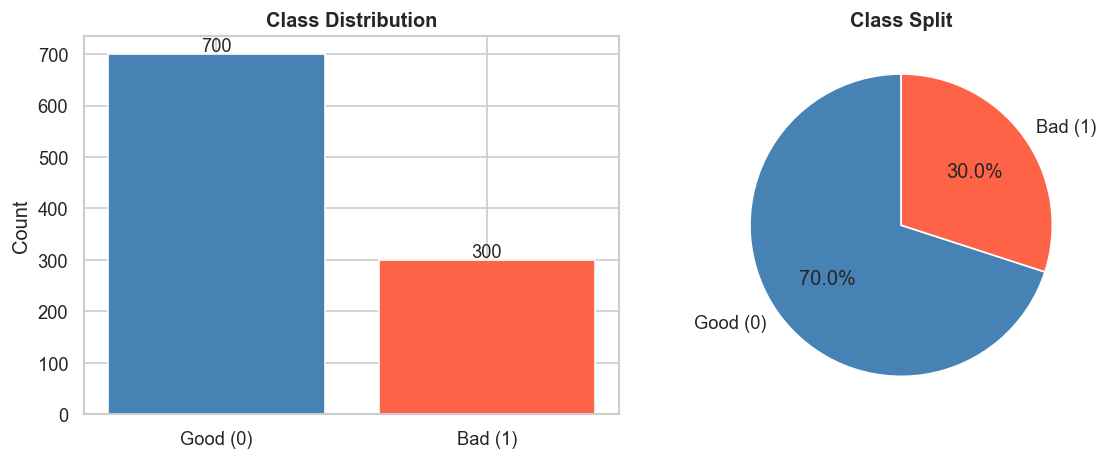

Good: 700 (70.0%)
Bad:  300 (30.0%)

Note: class imbalance present — we will use class_weight="balanced" during training.


In [13]:
target_counts = df['target'].value_counts()
labels = ['Good (0)', 'Bad (1)']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(labels, target_counts.values, color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Class Distribution', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', fontsize=11)

axes[1].pie(target_counts.values, labels=labels, autopct='%1.1f%%',
            colors=['steelblue', 'tomato'], startangle=90)
axes[1].set_title('Class Split', fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Good: {target_counts[0]} ({target_counts[0]/len(df):.1%})')
print(f'Bad:  {target_counts[1]} ({target_counts[1]/len(df):.1%})')
print('\nClass imbalance present — using class_weight="balanced" in training.')

## Numerical features vs. credit risk

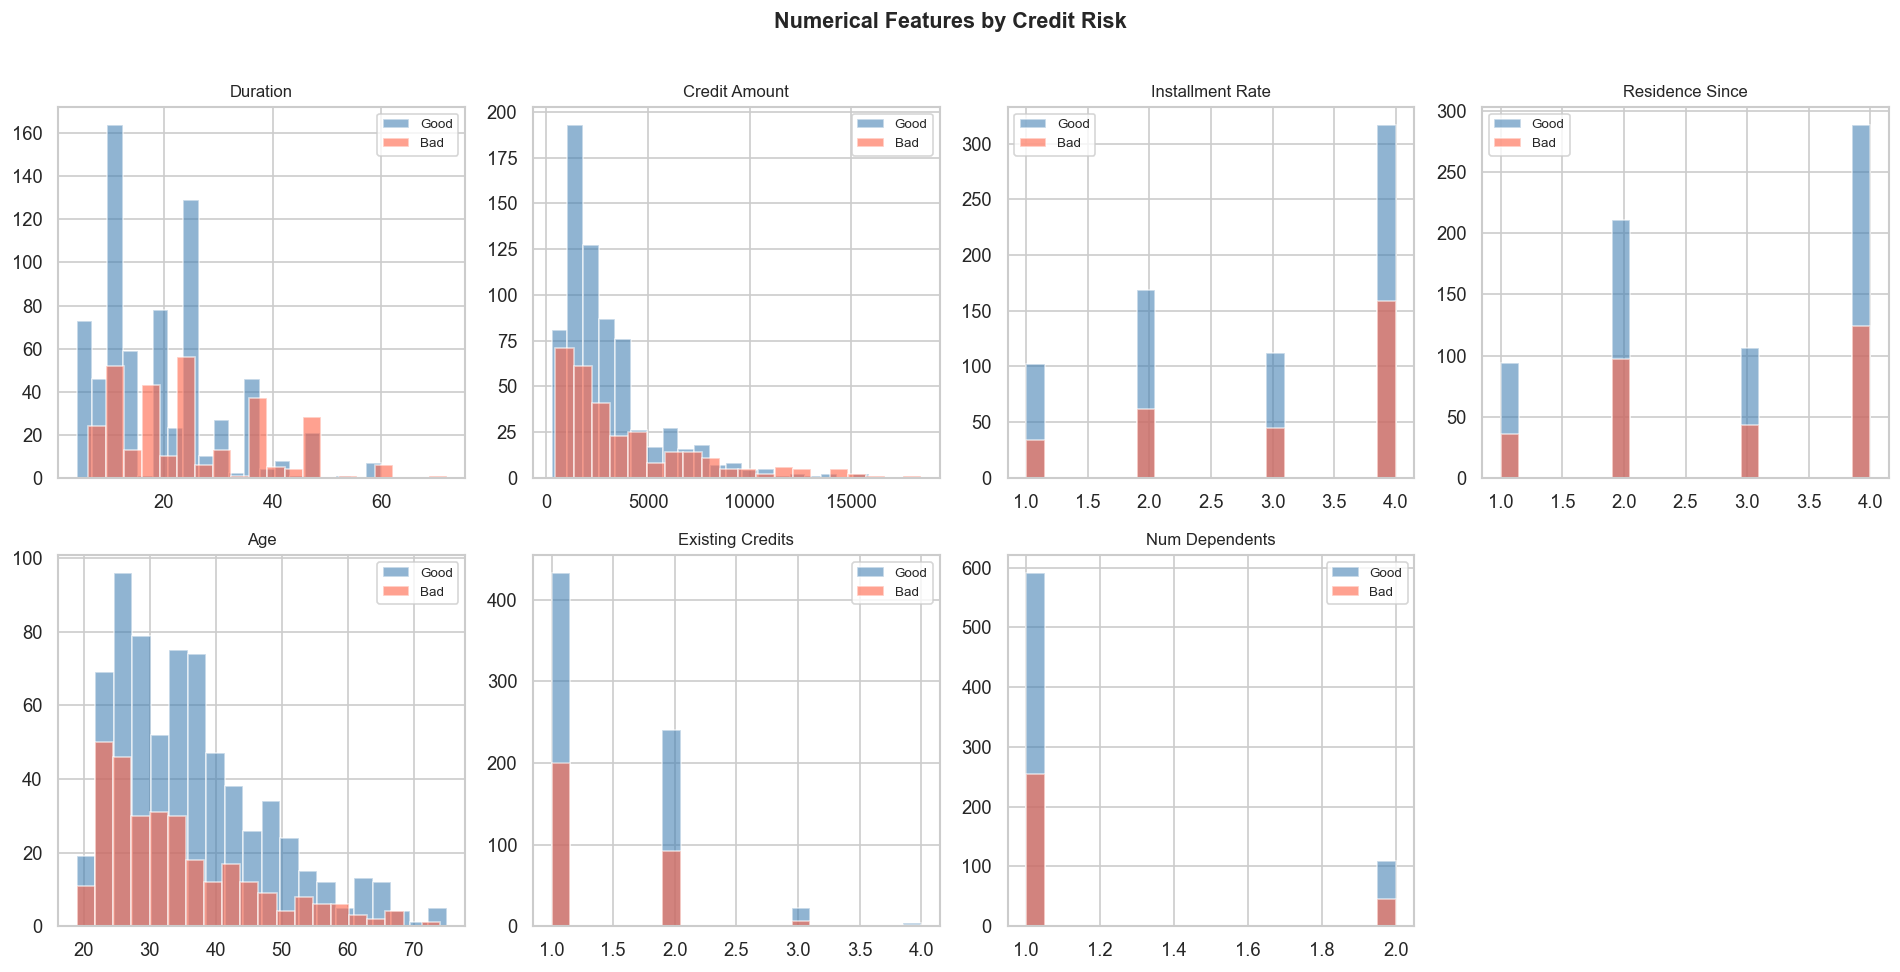

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(NUMERICAL_COLS):
    for label, color in zip([0, 1], ['steelblue', 'tomato']):
        axes[i].hist(
            df[df['target'] == label][col],
            bins=20, alpha=0.6, color=color,
            label='Good' if label == 0 else 'Bad'
        )
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=10)
    axes[i].legend(fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Numerical Features by Credit Risk', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**Duration** and **credit amount** show the clearest separation: Bad applicants tend to have longer loans and borrow more. Age skews slightly younger for bad applicants. That said, none of these alone cleanly separates the classes, which is why we need a model.

## Correlation heatmap

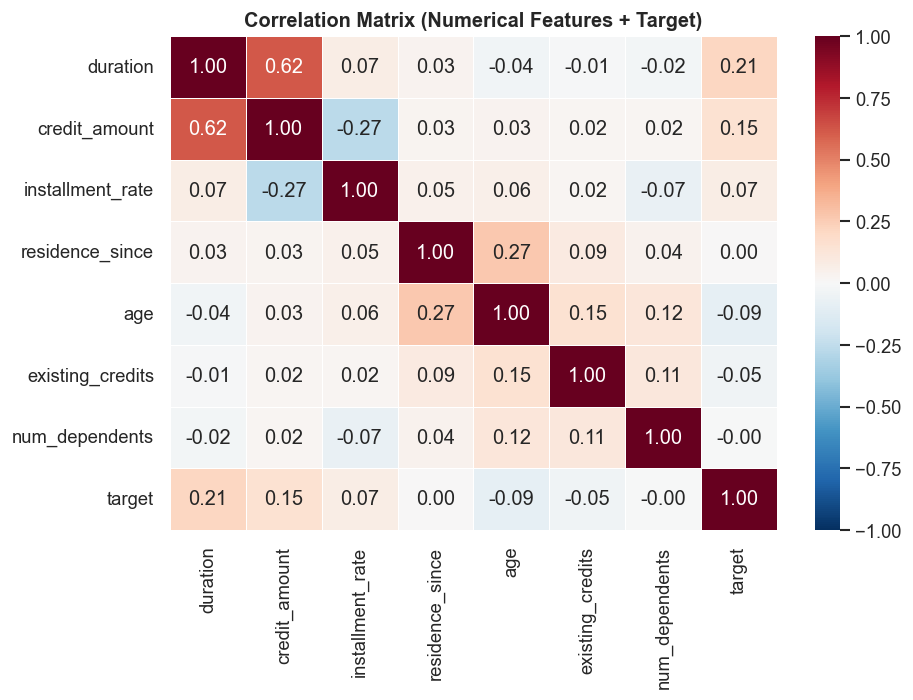

Correlation with target (sorted):
duration            0.215
credit_amount       0.155
installment_rate    0.072
residence_since     0.003
num_dependents     -0.003
existing_credits   -0.046
age                -0.091
Name: target, dtype: float64


In [15]:
corr_cols = NUMERICAL_COLS + ['target']
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
mask = pd.DataFrame(False, index=corr.index, columns=corr.columns)
sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='RdBu_r',
    vmin=-1, vmax=1, linewidths=0.5
)
plt.title('Correlation Matrix (Numerical Features + Target)', fontweight='bold')
plt.tight_layout()
plt.show()

print('Correlation with target (sorted):')
print(corr['target'].drop('target').sort_values(ascending=False).round(3))

## Top categorical features

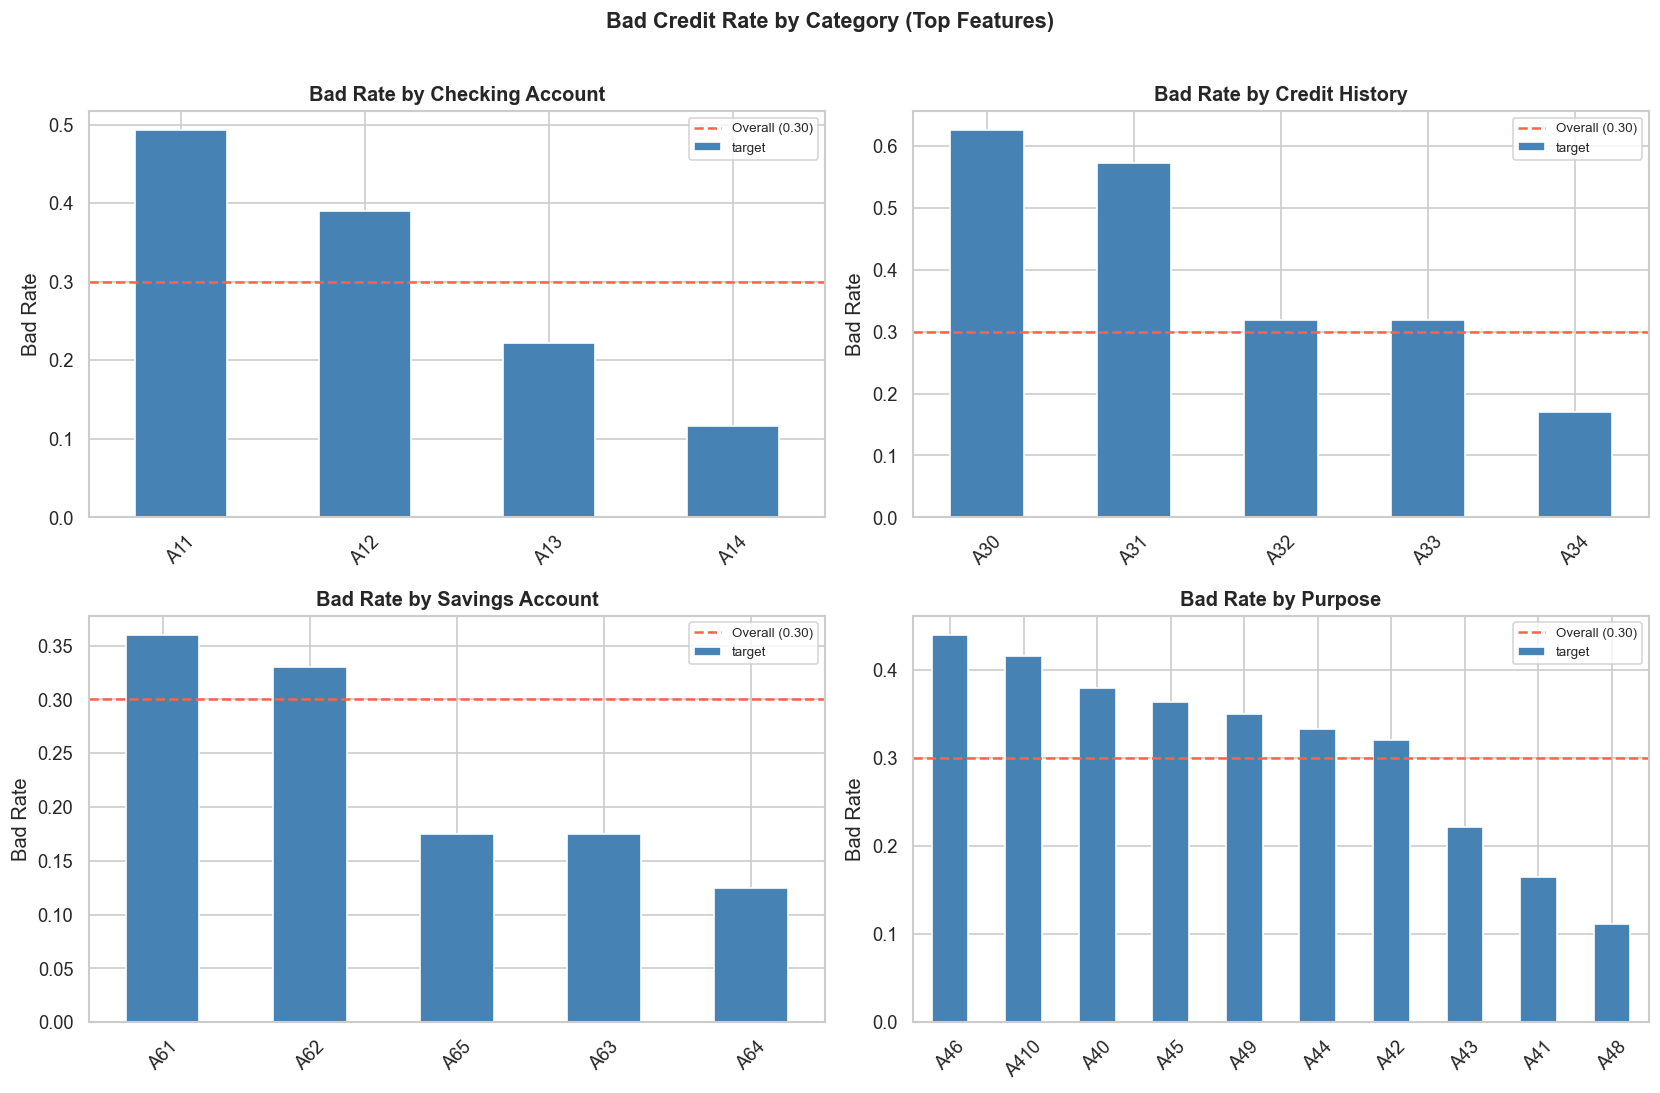

In [16]:
top_cats = ['checking_account', 'credit_history', 'savings_account', 'purpose']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(top_cats):
    bad_rate = df.groupby(col)['target'].mean().sort_values(ascending=False)
    bad_rate.plot(kind='bar', ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(f'Bad Rate by {col.replace("_", " ").title()}', fontweight='bold')
    axes[i].set_ylabel('Bad Rate')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].axhline(df['target'].mean(), color='tomato', linestyle='--', label=f'Overall ({df["target"].mean():.2f})')
    axes[i].legend(fontsize=8)

plt.suptitle('Bad Credit Rate by Category (Top Features)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## Takeaways

The 70/30 split is manageable. Loan duration, credit amount, checking account status, and credit history all look like useful predictors. No missing values, so preprocessing is straightforward.